# Five minute feature engineering

This notebook builds model inputs from the local SPY and QQQ Parquet files. Features use information available when the current five minute bar closes. The target is the following bar’s open to close direction, so the trade begins at the next bar open. Missing bars remain missing; no values are interpolated.


In [ ]:
# Find the project root so paths work from either the root or notebooks folder.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pandas_market_calendars as mcal

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(project_root / "python_code"))
from feature_engineering import (
    FEATURE_COLUMNS, TARGET_COLUMNS, add_predictors,
    build_model_frame, select_scheduled_bars,
)

data_dir = project_root / "data"
print("Project root:", project_root)


In [2]:
# Read the cleaned bars and make the exchange schedule for their actual date range.
qqq_source = pd.read_parquet(data_dir / "QQQ_clean_5min.parquet")
spy_source = pd.read_parquet(data_dir / "SPY_clean_5min.parquet")
start_date = min(qqq_source["datetime"].min(), spy_source["datetime"].min()).date()
end_date = max(qqq_source["datetime"].max(), spy_source["datetime"].max()).date()
schedule = mcal.get_calendar("NYSE").schedule(
    start_date=start_date, end_date=end_date
)

for name, source in [("QQQ", qqq_source), ("SPY", spy_source)]:
    print(f"{name}: {len(source):,} rows; {source['datetime'].min()} to {source['datetime'].max()}")
    print("Columns:", source.columns.tolist())


QQQ: 89,745 rows; 2022-03-07 09:30:00 to 2026-10-16 15:55:00
Columns: ['datetime', 'Open', 'High', 'Low', 'Close', 'Volume', 'source']
SPY: 89,750 rows; 2022-03-07 09:30:00 to 2026-10-16 15:55:00
Columns: ['datetime', 'Open', 'High', 'Low', 'Close', 'Volume', 'source']


In [3]:
# Keep scheduled bars, build the final target and predictors, then count usable rows.
qqq_research = select_scheduled_bars(qqq_source, schedule)
spy_research = select_scheduled_bars(spy_source, schedule)
qqq_model = build_model_frame(qqq_research)
spy_model = build_model_frame(spy_research)

assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS)
assert all(column not in FEATURE_COLUMNS for column in ("datetime", "source"))

summary = []
for name, frame in [("QQQ", qqq_model), ("SPY", spy_model)]:
    complete = frame.dropna(subset=[*FEATURE_COLUMNS, "target"])
    summary.append({
        "ETF": name,
        "Research rows": len(frame),
        "Valid next-bar targets": int(frame["target"].notna().sum()),
        "Rows with complete features and target": len(complete),
        "Rows excluded for unavailable features/target": len(frame) - len(complete),
        "Feature columns": len(FEATURE_COLUMNS),
    })
display(pd.DataFrame(summary).set_index("ETF"))
print("Features:", list(FEATURE_COLUMNS))


,Research rows,Valid next-bar targets,Rows with complete features and target,Rows excluded for unavailable features/target,Feature columns
ETF,,,,,
QQQ,89712,88330,72181,17531,11
SPY,89729,88342,72148,17581,11


Features: ['return_1_bar', 'return_3_bars', 'return_6_bars', 'realized_volatility_12_bars', 'bar_range_pct', 'close_location_in_bar', 'log_volume', 'log_volume_change_1_bar', 'minutes_since_open', 'time_of_day_sin', 'time_of_day_cos']


## Final target class balance

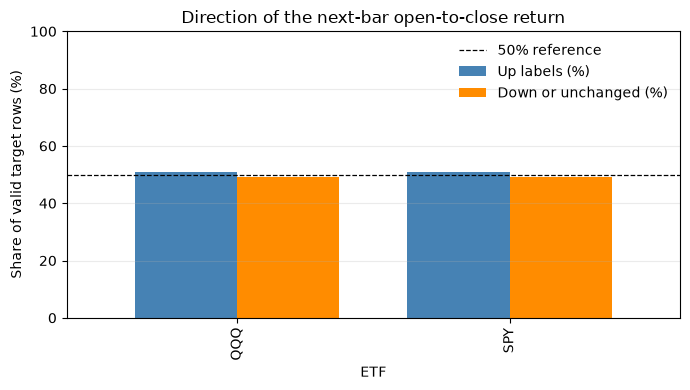

,ETF,Up labels (%),Down or unchanged (%),Valid target rows
0,QQQ,50.798143,49.201857,88330
1,SPY,50.852369,49.147631,88342


In [4]:
# Count only rows with a valid next-bar open-to-close target.
target_balance = []
for ticker, frame in [('QQQ', qqq_model), ('SPY', spy_model)]:
    labels = frame['target'].dropna().astype(int)
    target_balance.append({
        'ETF': ticker,
        'Up labels (%)': labels.mean() * 100,
        'Down or unchanged (%)': (1 - labels.mean()) * 100,
        'Valid target rows': len(labels),
    })
target_balance = pd.DataFrame(target_balance)

# A 50% reference makes any class imbalance easy to see at a glance.
ax = target_balance.set_index('ETF')[['Up labels (%)', 'Down or unchanged (%)']].plot(
    kind='bar', figsize=(7, 4), color=['steelblue', 'darkorange'], width=0.75
)
ax.axhline(50, color='black', linestyle='--', linewidth=0.9, label='50% reference')
ax.set_ylim(0, 100)
ax.set_title('Direction of the next-bar open-to-close return')
ax.set_ylabel('Share of valid target rows (%)')
ax.set_xlabel('ETF')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
target_balance

## Leakage check

The following check alters only later observations and confirms that earlier feature values are unchanged. The forward target columns are kept outside the explicit feature list. A prediction is made after the current bar closes; its target return starts at the next bar open and ends at that bar close.


In [5]:
# Change only later bars; earlier predictors should stay exactly the same.
for name, source in [("QQQ", qqq_research), ("SPY", spy_research)]:
    baseline = add_predictors(source)
    cutoff = source["datetime"].iloc[len(source) // 2]
    changed_future = source.copy()
    future = changed_future["datetime"] > cutoff
    for column in ["Open", "High", "Low", "Close"]:
        changed_future.loc[future, column] *= 1.25
    changed_future.loc[future, "Volume"] *= 2
    altered = add_predictors(changed_future)
    before_cutoff = baseline["datetime"] <= cutoff
    np.testing.assert_allclose(
        baseline.loc[before_cutoff, list(FEATURE_COLUMNS)].to_numpy(dtype=float),
        altered.loc[before_cutoff, list(FEATURE_COLUMNS)].to_numpy(dtype=float),
        equal_nan=True, rtol=0, atol=0,
    )
    print(f"{name}: earlier features unchanged when later bars are altered")

for name, frame in [("QQQ", qqq_model), ("SPY", spy_model)]:
    valid = frame.dropna(subset=["target"])
    assert (valid["next_datetime"].sub(valid["datetime"]) == pd.Timedelta(minutes=5)).all()
    assert (valid["next_datetime"].dt.date == valid["datetime"].dt.date).all()
    print(f"{name}: all valid targets use the next bar open-to-close within the same session")


QQQ: earlier features unchanged when later bars are altered


SPY: earlier features unchanged when later bars are altered
QQQ: all valid targets use the next bar open-to-close within the same session
SPY: all valid targets use the next bar open-to-close within the same session
